<a href="https://colab.research.google.com/github/Kevinaryadandy/23040700094/blob/main/KELOMPOK_3_PROYEK_AKHIR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

#Load dataset
df = pd.read_csv('konsultasi_karir.csv')

#Cek Dimensi
print("=== DIMENSI DATASET ===")
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")

#Cek Missing Values
print("\n=== MISSING VALUES ===")
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])

#Cek Informasi Kolom & Tipe Data
print("\n=== INFO KOLOM ===")
print(df.info())

=== DIMENSI DATASET ===
Jumlah Baris: 2975
Jumlah Kolom: 40

=== MISSING VALUES ===
                    Missing Count  Percentage (%)
Kode Referensi                463       15.563025
Tempat Magang                 463       15.563025
EMAIL INFO PROGRAM           1689       56.773109

=== INFO KOLOM ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2975 entries, 0 to 2974
Data columns (total 40 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               2975 non-null   object 
 1   Nama Lengkap            2975 non-null   object 
 2   Perguruan Tinggi        2975 non-null   object 
 3   Ikut Program VINIX7?    2975 non-null   object 
 4   Kode Referensi          2512 non-null   object 
 5   Program Studi           2975 non-null   object 
 6   Semester                2975 non-null   int64  
 7   IPK                     2975 non-null   int64  
 8   Tempat Magang           2512 non-null   object 
 9   D

In [ ]:
# Membuat copy dataframe agar data original aman
df_clean = df.copy()

print("=== 5 PERMASALAHAN UTAMA DATA & SOLUSI PERBAIKANNYA ===")
print("1. Missing values pada kolom opsional (Kode Referensi, Tempat Magang, EMAIL INFO PROGRAM).")
print("2. Format Timestamp yang belum terstandarisasi sebagai datetime.")
print("3. Inkonsistensi teks/kardinalitas pada kolom kategorikal.")
print("4. Potensi outlier pada kolom skor modular dan total skor.")
print("5. Duplikasi baris data yang tidak disengaja (jika ada).\n")

# Penanganan Masalah 1 & 5: Imputasi missing values & hapus duplikat
df_clean.drop_duplicates(inplace=True)
df_clean['Kode Referensi'] = df_clean['Kode Referensi'].fillna('Tidak Ada')
df_clean['Tempat Magang'] = df_clean['Tempat Magang'].fillna('Belum Magang')
df_clean['EMAIL INFO PROGRAM'] = df_clean['EMAIL INFO PROGRAM'].fillna('Tidak Diketahui')

# Penanganan Masalah 2: Konversi Timestamp
df_clean['Timestamp'] = pd.to_datetime(df_clean['Timestamp'], errors='coerce')

if 'Jalur Karir' in df_clean.columns:
    df_clean['Jalur Karir'] = df_clean['Jalur Karir'].str.strip().str.lower()
if 'Archetype' in df_clean.columns:
    df_clean['Archetype'] = df_clean['Archetype'].str.strip()

print("Data cleaning tahap awal selesai. Ukuran bersih:", df_clean.shape)

=== 5 PERMASALAHAN UTAMA DATA & SOLUSI PERBAIKANNYA ===
1. Missing values pada kolom opsional (Kode Referensi, Tempat Magang, EMAIL INFO PROGRAM).
2. Format Timestamp yang belum terstandarisasi sebagai datetime.
3. Inkonsistensi teks/kardinalitas pada kolom kategorikal.
4. Potensi outlier pada kolom skor modular dan total skor.
5. Duplikasi baris data yang tidak disengaja (jika ada).

Data cleaning tahap awal selesai. Ukuran bersih: (2975, 40)


In [ ]:
# Target Variabel
target_col = 'Verdict Kesiapan'

print(f"=== DISTRIBUSI TARGET ({target_col}) ===")
target_counts = df_clean[target_col].value_counts(dropna=False)
print(target_counts)

print("\nPersentase Distribusi Kelas:")
print((target_counts / len(df_clean)) * 100)

=== DISTRIBUSI TARGET (Verdict Kesiapan) ===
Verdict Kesiapan
Siap Masuk Industri    2048
Hampir Siap             631
Sangat Siap             288
Perlu Persiapan           8
Name: count, dtype: int64

Persentase Distribusi Kelas:
Verdict Kesiapan
Siap Masuk Industri    68.840336
Hampir Siap            21.210084
Sangat Siap             9.680672
Perlu Persiapan         0.268908
Name: count, dtype: float64


In [ ]:
# Menentukan kolom target dan fitur
y = df_clean[target_col]

# Drop kolom target, timestamp, atau kolom teks terbuka yang tidak relevan dari fitur X
drop_cols = [target_col, 'Timestamp', 'EMAIL INFO PROGRAM', 'Kode Referensi']


X = df_clean.drop(columns=[col for col in drop_cols if col in df_clean.columns])

print("=== FITUR INPUT (X) SIAP ===")
print(f"Jumlah Fitur X: {X.shape[1]} kolom")
print(X.dtypes.value_counts())

=== FITUR INPUT (X) SIAP ===
Jumlah Fitur X: 36 kolom
object    18
int64     18
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Memisahkan kolom numerik dan kategorikal
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Kolom Numerik ({len(num_cols)}): {num_cols}")
print(f"Kolom Kategorikal ({len(cat_cols)}): {cat_cols}")

# Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Preprocessor untuk Numerik (Imputasi Median + Scaling)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessor untuk Kategorikal (Imputasi Modus + OneHotEncoder dengan handle_unknown='ignore')
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Menggabungkan dalam ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ])

print("\nColumnTransformer berhasil dirancang dan siap dihubungkan dengan model Machine Learning (Supervised/Unsupervised)!")

Kolom Numerik (18): ['Semester', 'IPK', 'Total Score', 'Skor M1 (Background)', 'Skor M2 (Skills)', 'Skor M3 (Industry)', 'Skor M4 (Interest)', 'Skor M5 (Compass)', 'Skor M6 (Company)', 'Skor M7 (Branding)', 'Skor M8 (Ambisi)', 'Skor M9 (Resiliensi)', 'Ekspektasi Gaji', 'Minat Wirausaha', 'Rencana S2/Sertifikasi', 'Frekuensi Belajar', 'Kesiapan Interview', 'Level Bahasa Inggris']
Kolom Kategorikal (18): ['Nama Lengkap', 'Perguruan Tinggi', 'Ikut Program VINIX7?', 'Program Studi', 'Tempat Magang', 'Dream Job', 'Archetype', 'Jalur Karir', 'Bidang Minat', 'Work Values', 'Work Style', 'Cognitive Style', 'Motivasi', 'Ukuran Perusahaan', 'Kultur Kerja', 'Preferensi Lokasi', 'Rekomendasi Industri 1', 'Rekomendasi Industri 2']

ColumnTransformer berhasil dirancang dan siap dihubungkan dengan model Machine Learning (Supervised/Unsupervised)!


# Menentukan Fitur Clustering

In [ ]:
numeric_cluster_cols = [
    'Semester'
]

categorical_cluster_cols = [
    'Work Style',
    'Cognitive Style',
    'Motivasi',
    'Ukuran Perusahaan',
    'Kultur Kerja',
    'Preferensi Lokasi'
]

multilabel_cluster_cols = [
    'Bidang Minat',
    'Work Values'
]

#Menggabungkan daftar fitur
cluster_cols = (
    numeric_cluster_cols +
    categorical_cluster_cols +
    multilabel_cluster_cols
)

#Mengecek kolom
missing_columns = [
    col for col in cluster_cols
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(f"Kolom tidak ditemukan: {missing_columns}")

#Mengambil data clustering
cluster_data = df_clean[cluster_cols].copy()

for col in categorical_cluster_cols + multilabel_cluster_cols:
    cluster_data[col] = (
        cluster_data[col].astype("string").str.strip()
    )

print("=== DATA CLUSTERING ===")
print("Jumlah baris dan kolom:", cluster_data.shape)

print("\n=== TIPE DATA ===")
print(cluster_data.dtypes)

print("\n=== MISSING VALUES ===")
print(cluster_data.isnull().sum())

print("\n=== CONTOH DATA ===")
display(cluster_data.head())


=== DATA CLUSTERING ===
Jumlah baris dan kolom: (2975, 9)

=== TIPE DATA ===
Semester                      int64
Work Style           string[python]
Cognitive Style      string[python]
Motivasi             string[python]
Ukuran Perusahaan    string[python]
Kultur Kerja         string[python]
Preferensi Lokasi    string[python]
Bidang Minat         string[python]
Work Values          string[python]
dtype: object

=== MISSING VALUES ===
Semester             0
Work Style           0
Cognitive Style      0
Motivasi             0
Ukuran Perusahaan    0
Kultur Kerja         0
Preferensi Lokasi    0
Bidang Minat         0
Work Values          0
dtype: int64

=== CONTOH DATA ===


,Semester,Work Style,Cognitive Style,Motivasi,Ukuran Perusahaan,Kultur Kerja,Preferensi Lokasi,Bidang Minat,Work Values
0,5,big,creative,growth,big,agile,hybrid,"tech, health, industry","wlb, growth, creative"
1,1,small,social,prestige,big,agile,hybrid,"finance, biz, edu","salary, wlb, impact"
2,3,flex,analytical,growth,startup,result,hybrid,"tech, ecom",flex
3,3,flex,analytical,impact,flex,collab,hybrid,"creative, edu, social","impact, creative, flex"
4,3,solo,analytical,money,flex,formal,onsite,"edu, tech, govt","stability, salary, wlb"


# PreProcessing Pipeline untuk Clustering

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer

# 1. Pipeline untuk data numerik
numeric_transformer_cluster = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Pipeline untuk data kategorikal
categorical_transformer_cluster = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# 3. Menggabungkan seluruh preprocessing
preprocessor_cluster = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_cluster, numeric_cluster_cols),

        ('cat', categorical_transformer_cluster, categorical_cluster_cols),

        ('bidang_minat', CountVectorizer(binary=True), 'Bidang Minat'),

        ('work_values', CountVectorizer(binary=True), 'Work Values')
    ],
    remainder='drop',
    sparse_threshold=0.0
)

# 4. Melakukan preprocessing pada data clustering
X_cluster_processed = preprocessor_cluster.fit_transform(cluster_data)

# 5. Memeriksa hasil preprocessing
print("=== HASIL PREPROCESSING CLUSTERING ===")
print("Dimensi sebelum preprocessing:", cluster_data.shape)
print("Dimensi setelah preprocessing:", X_cluster_processed.shape)

print("\nJumlah fitur hasil encoding:",
      len(preprocessor_cluster.get_feature_names_out()))

print("\nNama fitur hasil preprocessing:")
print(preprocessor_cluster.get_feature_names_out())

print("\nContoh hasil data numerik:")
display(pd.DataFrame(X_cluster_processed).head())


=== HASIL PREPROCESSING CLUSTERING ===
Dimensi sebelum preprocessing: (2975, 9)
Dimensi setelah preprocessing: (2975, 46)

Jumlah fitur hasil encoding: 46

Nama fitur hasil preprocessing:
['num__Semester' 'cat__Work Style_big' 'cat__Work Style_flex'
 'cat__Work Style_small' 'cat__Work Style_solo'
 'cat__Cognitive Style_analytical' 'cat__Cognitive Style_creative'
 'cat__Cognitive Style_social' 'cat__Cognitive Style_strategic'
 'cat__Motivasi_freedom' 'cat__Motivasi_growth' 'cat__Motivasi_impact'
 'cat__Motivasi_money' 'cat__Motivasi_prestige'
 'cat__Ukuran Perusahaan_big' 'cat__Ukuran Perusahaan_flex'
 'cat__Ukuran Perusahaan_mid' 'cat__Ukuran Perusahaan_startup'
 'cat__Kultur Kerja_agile' 'cat__Kultur Kerja_collab'
 'cat__Kultur Kerja_formal' 'cat__Kultur Kerja_result'
 'cat__Preferensi Lokasi_any' 'cat__Preferensi Lokasi_hybrid'
 'cat__Preferensi Lokasi_onsite' 'cat__Preferensi Lokasi_remote'
 'bidang_minat__biz' 'bidang_minat__creative' 'bidang_minat__ecom'
 'bidang_minat__edu' 'bida

,0,1,2,3,4,5,6,7,8,9,...,36,37,38,39,40,41,42,43,44,45
0,2.137698,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-2.248268,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,-0.055285,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.055285,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.055285,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0


Eskperimen : Menentukan jumlah cluster dengan model k-means


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.base import clone
import matplotlib.pyplot as plt
import pandas as pd

# Menyimpan hasil pengujian
hasil_clustering = []

# Menguji jumlah cluster dari 2 sampai 10
for k in range(2, 11):

    # Membuat pipeline preprocessing + KMeans
    pipeline_k = Pipeline(steps=[
        ('preprocessing', clone(preprocessor_cluster)),
        ('kmeans', KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ))
    ])

    # Melatih pipeline
    pipeline_k.fit(cluster_data)

    # Mengambil data hasil preprocessing
    X_k = pipeline_k.named_steps['preprocessing'].transform(
        cluster_data
    )

    # Mengambil label cluster
    labels_k = pipeline_k.named_steps['kmeans'].labels_

    # Silhouette dihitung dari sampel 1.000 responden agar lebih ringan.
    # Jadi, nilainya merupakan estimasi, bukan perhitungan seluruh data.
    # Menghitung Silhouette Score
    silhouette = silhouette_score(
        X_k,
        labels_k,
        sample_size=1000,
        random_state=42
    )

    # Mengambil nilai Inertia
    inertia = pipeline_k.named_steps['kmeans'].inertia_

    # Menyimpan hasil
    hasil_clustering.append({
        'Jumlah Cluster': k,
        'Inertia': inertia,
        'Silhouette Score': silhouette
    })

# Membuat tabel hasil
hasil_k = pd.DataFrame(hasil_clustering)

print("=== HASIL PENGUJIAN JUMLAH CLUSTER ===")
display(hasil_k.round(4))


=== HASIL PENGUJIAN JUMLAH CLUSTER ===


,Jumlah Cluster,Inertia,Silhouette Score
0,2,22672.0967,0.0813
1,3,21667.2024,0.0607
2,4,20924.4391,0.0497
3,5,20496.0937,0.0485
4,6,20131.3246,0.0454
5,7,19843.4800,0.0427
6,8,19618.7683,0.0395
7,9,19416.7026,0.0388
8,10,19147.7625,0.0409


Visualisasi clustering

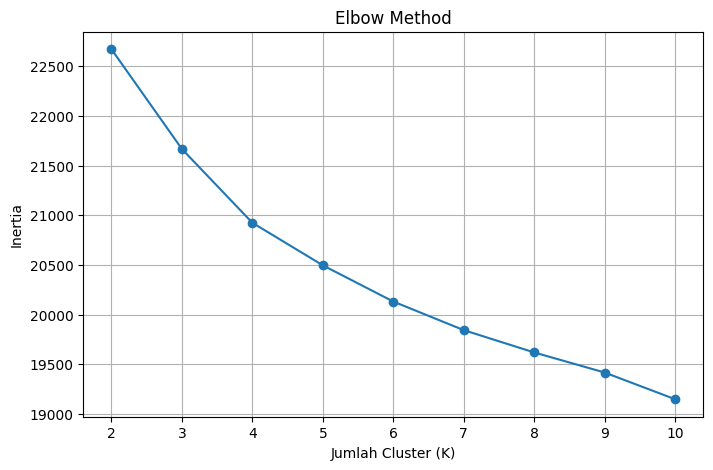

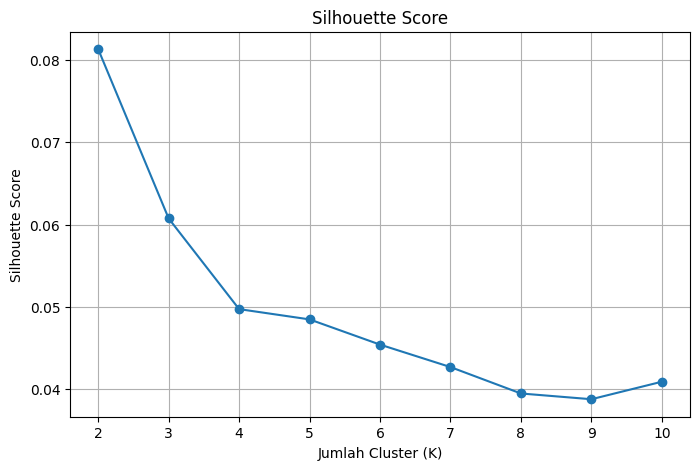

In [ ]:
# Grafik Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    hasil_k['Jumlah Cluster'],
    hasil_k['Inertia'],
    marker='o'
)

plt.title('Elbow Method')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


# Grafik Silhouette Score
plt.figure(figsize=(8, 5))

plt.plot(
    hasil_k['Jumlah Cluster'],
    hasil_k['Silhouette Score'],
    marker='o'
)

plt.title('Silhouette Score')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


In [ ]:
# Membandingkan cluster

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
import pandas as pd

# Kandidat jumlah cluster
k_candidates = [2, 3, 4]

# Menyimpan model
cluster_models = {}

for k in k_candidates:

    # Membuat pipeline clustering
    pipeline = Pipeline(steps=[
        ('preprocessing', clone(preprocessor_cluster)),
        ('kmeans', KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ))
    ])

    # Melatih model
    pipeline.fit(cluster_data)

    # Mengambil label cluster
    labels = pipeline.named_steps['kmeans'].labels_

    # Menyimpan model
    cluster_models[k] = pipeline

    # Menghitung jumlah anggota setiap cluster
    counts = pd.Series(labels).value_counts().sort_index()

    print(f"\n=== DISTRIBUSI CLUSTER K={k} ===")

    for cluster_id, jumlah in counts.items():

        persentase = jumlah / len(labels) * 100

        print(
            f"Cluster {cluster_id}: "
            f"{jumlah} mahasiswa "
            f"({persentase:.2f}%)"
        )



=== DISTRIBUSI CLUSTER K=2 ===
Cluster 0: 695 mahasiswa (23.36%)
Cluster 1: 2280 mahasiswa (76.64%)

=== DISTRIBUSI CLUSTER K=3 ===
Cluster 0: 539 mahasiswa (18.12%)
Cluster 1: 1185 mahasiswa (39.83%)
Cluster 2: 1251 mahasiswa (42.05%)

=== DISTRIBUSI CLUSTER K=4 ===
Cluster 0: 688 mahasiswa (23.13%)
Cluster 1: 426 mahasiswa (14.32%)
Cluster 2: 950 mahasiswa (31.93%)
Cluster 3: 911 mahasiswa (30.62%)


In [ ]:
import pandas as pd

def analisis_cluster(k):

    # Mengambil model yang sudah dilatih
    model = cluster_models[k]

    # Mengambil label cluster
    labels = model.named_steps['kmeans'].labels_

    # Menggabungkan label dengan data asli
    data_profil = cluster_data.copy()
    data_profil['Cluster'] = labels

    print(f"\n{'='*50}")
    print(f"ANALISIS KARAKTERISTIK CLUSTER K={k}")
    print(f"{'='*50}")

    # Analisis setiap cluster
    for cluster_id in sorted(data_profil['Cluster'].unique()):

        subset = data_profil[
            data_profil['Cluster'] == cluster_id
        ]

        print(f"\n--- CLUSTER {cluster_id} ---")
        print(f"Jumlah mahasiswa: {len(subset)}")

        # Analisis Semester
        print("\nSemester:")
        print("Median:", subset['Semester'].median())

        # Analisis kategori biasa
        print("\nKarakteristik kategorikal:")

        for col in categorical_cluster_cols:

            valid = subset[col].dropna().astype(str).str.strip()
            valid = valid[~valid.str.lower().isin(
                ['', '-', 'nan', 'none']
            )]

            if len(valid) > 0:

                #Mencari kategori yg sering muncul
                dominan = valid.value_counts().head(1)

                kategori = dominan.index[0]
                jumlah = dominan.iloc[0]
                persen = jumlah / len(valid) * 100

                print(
                    f"{col}: {kategori} "
                    f"({persen:.2f}%)"
                )

        # Analisis multi-label
        print("\nPilihan Bidang Minat dan Work Values:")

        for col in multilabel_cluster_cols:

            pilihan = (
                subset[col]
                .fillna('')
                .astype(str)
                .str.split(',')
                .explode()
                .str.strip()
            )

            pilihan = pilihan[
                ~pilihan.str.lower().isin(
                    ['', '-', 'nan', 'none']
                )
            ]

            top_pilihan = pilihan.value_counts().head(3)

            print(f"\n{col}:")

            for nama, jumlah in top_pilihan.items():

                persen = jumlah / len(subset) * 100

                print(
                    f"- {nama}: "
                    f"{jumlah} kemunculan "
                    f"({persen:.2f}%)"
                )


# Membandingkan karakteristik K=2, K=3, K=4
for k in [2, 3, 4]:
    analisis_cluster(k)



ANALISIS KARAKTERISTIK CLUSTER K=2

--- CLUSTER 0 ---
Jumlah mahasiswa: 695

Semester:
Median: 4.0

Karakteristik kategorikal:
Work Style: small (35.54%)
Cognitive Style: analytical (49.21%)
Motivasi: money (46.19%)
Ukuran Perusahaan: flex (50.94%)
Kultur Kerja: collab (47.48%)
Preferensi Lokasi: hybrid (50.65%)

Pilihan Bidang Minat dan Work Values:

Bidang Minat:
- tech: 372 kemunculan (53.53%)
- creative: 252 kemunculan (36.26%)
- biz: 240 kemunculan (34.53%)

Work Values:
- salary: 479 kemunculan (68.92%)
- wlb: 440 kemunculan (63.31%)
- learning: 217 kemunculan (31.22%)

--- CLUSTER 1 ---
Jumlah mahasiswa: 2280

Semester:
Median: 3.0

Karakteristik kategorikal:
Work Style: small (39.82%)
Cognitive Style: analytical (53.25%)
Motivasi: money (47.41%)
Ukuran Perusahaan: flex (46.67%)
Kultur Kerja: collab (44.69%)
Preferensi Lokasi: hybrid (53.86%)

Pilihan Bidang Minat dan Work Values:

Bidang Minat:
- tech: 1224 kemunculan (53.68%)
- biz: 888 kemunculan (38.95%)
- finance: 839 kemu

## Pemilihan jumlah cluster
Berdasarkan eksperimen, nilai Silhouette Score tertinggi diperoleh pada K=2 sebesar 0,0813. Nilai untuk K=3 adalah 0,0607, sedangkan K=4 adalah 0,0497. Silhouette Score dihitung menggunakan sampel 1.000 responden sehingga nilainya merupakan estimasi.

Meskipun K=2 memperoleh skor tertinggi, karakteristik kedua kelompok pada K=2 relatif mirip. Pada K=3, analisis profil menunjukkan dua kelompok dengan kecenderungan kultur kerja yang lebih mudah dibedakan: Cluster 1 cenderung kolaboratif (94,18%) dan Cluster 2 cenderung formal (78,10%). Cluster 0 memiliki karakteristik yang lebih beragam.

K=4 menghasilkan pembagian anggota yang sedikit lebih merata dan segmentasi yang lebih rinci, tetapi menambah kompleksitas serta menghasilkan beberapa kelompok yang karakteristiknya tidak sejelas dua kelompok utama tersebut. Oleh karena itu, K=3 dipilih sebagai kompromi untuk segmentasi eksploratif yang lebih mudah diinterpretasikan, bukan karena memiliki Silhouette Score tertinggi atau distribusi anggota paling seimbang.

Pada K=3, jumlah anggota masing-masing cluster adalah 539, 1.185, dan 1.251 mahasiswa.

Nilai Silhouette Score K=3 sebesar 0,0607 masih rendah. Hal ini menunjukkan bahwa pemisahan antarcluster belum kuat dan sebagian karakteristik responden masih saling tumpang tindih. Karena itu, hasil clustering perlu dipahami sebagai segmentasi eksploratif, bukan kelompok yang terpisah secara tegas.

In [ ]:
# Menentukan jumlah cluster final
k_final = 3

# Mengambil pipeline K-Means K=3
final_cluster_model = cluster_models[k_final]

# Melakukan prediksi cluster
cluster_labels = final_cluster_model.predict(cluster_data)

# Menambahkan label cluster ke dataset
hasil_clustering = df_clean.copy()
hasil_clustering['Cluster'] = cluster_labels

# Melihat jumlah anggota setiap cluster
print("=== HASIL CLUSTERING FINAL ===")

print(
    hasil_clustering['Cluster']
    .value_counts()
    .sort_index()
)

# Melihat contoh hasil
display(
    hasil_clustering[
        cluster_cols + ['Cluster']
    ].head()
)


=== HASIL CLUSTERING FINAL ===
Cluster
0     539
1    1185
2    1251
Name: count, dtype: int64


,Semester,Work Style,Cognitive Style,Motivasi,Ukuran Perusahaan,Kultur Kerja,Preferensi Lokasi,Bidang Minat,Work Values,Cluster
0,5,big,creative,growth,big,agile,hybrid,"tech, health, industry","wlb, growth, creative",2
1,1,small,social,prestige,big,agile,hybrid,"finance, biz, edu","salary, wlb, impact",0
2,3,flex,analytical,growth,startup,result,hybrid,"tech, ecom",flex,2
3,3,flex,analytical,impact,flex,collab,hybrid,"creative, edu, social","impact, creative, flex",1
4,3,solo,analytical,money,flex,formal,onsite,"edu, tech, govt","stability, salary, wlb",2


#### Modelling & Tuning

#### Tujuan
Membangun model klasifikasi untuk memprediksi **Verdict Kesiapan** mahasiswa (4 kelas: *Sangat Siap*, *Siap Masuk Industri*, *Hampir Siap*, *Perlu Persiapan*) dan membandingkan beberapa algoritma secara sistematis.

#### Alur Tahapan
1. Pembagian data latih dan data uji
2. Pemilihan 3 algoritma pembanding
3. Eksperimen 1: model dengan seluruh fitur
4. Eksperimen 2: diagnosis kebocoran data (*data leakage*)
5. Eksperimen 3 (final): cross-validation dan hyperparameter tuning tanpa fitur bocor
6. Evaluasi pada data uji dibandingkan dengan baseline
7. Interpretasi model

#### Strategi Evaluasi
- **Pembagian data:** 80% data latih (2.380 sampel) dan 20% data uji (595 sampel).
- **Cross-validation:** 5-fold *stratified*, yaitu proporsi kelas dijaga di setiap fold.
- **Metrik utama:** *F1 Macro*, karena distribusi kelas sangat timpang (kelas *Perlu Persiapan* hanya 8 dari 2.975 data). Akurasi saja dapat menyesatkan pada data tidak seimbang.
- **Penanganan ketimpangan kelas:** `class_weight='balanced'` pada semua model.
- **Praproses:** standardisasi fitur numerik dan *one-hot encoding* fitur kategorikal dalam satu `Pipeline`, sehingga praproses dipelajari hanya dari data latih di setiap fold dan tidak terjadi kebocoran dari data validasi.
- **Baseline:** `DummyClassifier` yang selalu memprediksi kelas terbanyak.

#### Pemilihan Algoritma
Tiga algoritma dipilih karena mewakili keluarga model yang berbeda:

| Algoritma | Jenis | Alasan Dipilih |
|---|---|---|
| Logistic Regression | Model linear | Sederhana, cepat, dan koefisiennya mudah diinterpretasi |
| Decision Tree | Model berbasis pohon tunggal | Aturan keputusannya dapat dibaca langsung |
| Random Forest | Ensemble pohon | Umumnya lebih stabil dan tahan terhadap overfitting dibanding pohon tunggal |

#### Eksperimen 1: Seluruh Fitur
Ketiga model pertama kali dilatih menggunakan seluruh 35 fitur dan dievaluasi dengan 5-fold cross-validation, lalu di-*tuning* dengan `GridSearchCV`.

**Temuan:** performa mendekati sempurna. Decision Tree dengan `max_depth=3` saja sudah mencapai *accuracy* dan *F1* sebesar 1,00 pada data uji. Pohon sedangkal itu tidak mungkin mempelajari pola yang kompleks, sehingga hasil ini dicurigai sebagai tanda **kebocoran data**.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 3 algoritma yang dibandingkan
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42)
}

# 5-fold cross-validation yang menjaga proporsi kelas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hasil_cv = []
for nama, model in models.items():
    pipe = Pipeline(steps=[('preprocessing', preprocessor), ('model', model)])
    skor = cross_validate(pipe, X_train, y_train, cv=cv,
                          scoring=['accuracy', 'f1_macro', 'f1_weighted'], n_jobs=-1)
    hasil_cv.append({
        'Model': nama,
        'Accuracy': skor['test_accuracy'].mean(),
        'F1 Macro': skor['test_f1_macro'].mean(),
        'F1 Weighted': skor['test_f1_weighted'].mean()
    })

hasil_cv = pd.DataFrame(hasil_cv)
print("=== HASIL CROSS-VALIDATION (sebelum tuning) ===")
display(hasil_cv.round(4))

=== HASIL CROSS-VALIDATION (sebelum tuning) ===


,Model,Accuracy,F1 Macro,F1 Weighted
0,Logistic Regression,0.9996,0.9831,0.9995
1,Decision Tree,1.0000,1.0000,1.0000
2,Random Forest,0.9971,0.7479,0.9958


In [ ]:
from sklearn.model_selection import GridSearchCV

# Grid parameter dibuat kecil supaya cepat
param_grid = {
    'Logistic Regression': {
        'model__C': [0.1, 1, 10]
    },
    'Decision Tree': {
        'model__max_depth': [3, 5, 10, None],
        'model__min_samples_leaf': [1, 5, 10]
    },
    'Random Forest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [1, 3]
    }
}

best_models = {}
hasil_tuning = []

for nama, model in models.items():
    pipe = Pipeline(steps=[('preprocessing', preprocessor), ('model', model)])
    grid = GridSearchCV(pipe, param_grid[nama], cv=cv, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)

    best_models[nama] = grid.best_estimator_
    hasil_tuning.append({
        'Model': nama,
        'F1 Macro CV (setelah tuning)': grid.best_score_,
        'Parameter Terbaik': grid.best_params_
    })

hasil_tuning = pd.DataFrame(hasil_tuning)
print("=== HASIL TUNING ===")
display(hasil_tuning)

=== HASIL TUNING ===


,Model,F1 Macro CV (setelah tuning),Parameter Terbaik
0,Logistic Regression,0.983087,{'model__C': 0.1}
1,Decision Tree,1.000000,"{'model__max_depth': 3, 'model__min_samples_le..."
2,Random Forest,0.978074,"{'model__max_depth': 5, 'model__min_samples_le..."


=== PERFORMA DI DATA UJI ===


,Model,Accuracy,F1 Macro,F1 Weighted
0,Logistic Regression,0.9983,0.9490,0.9985
1,Decision Tree,1.0000,1.0000,1.0000
2,Random Forest,0.9916,0.9427,0.9918



Model terbaik: Decision Tree

                     precision    recall  f1-score   support

        Hampir Siap       1.00      1.00      1.00       126
    Perlu Persiapan       1.00      1.00      1.00         2
        Sangat Siap       1.00      1.00      1.00        58
Siap Masuk Industri       1.00      1.00      1.00       409

           accuracy                           1.00       595
          macro avg       1.00      1.00      1.00       595
       weighted avg       1.00      1.00      1.00       595



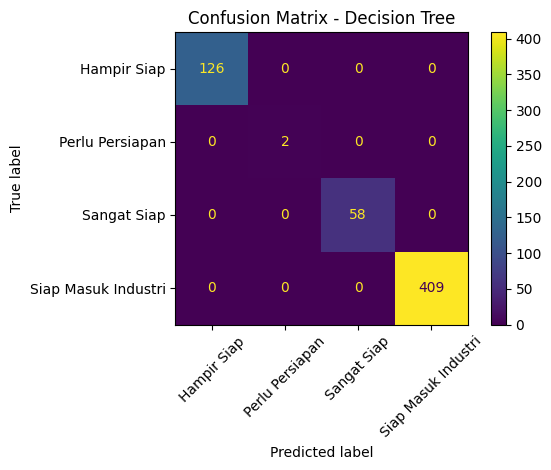

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Evaluasi ketiga model tuned pada data uji
hasil_test = []
for nama, model in best_models.items():
    y_pred = model.predict(X_test)
    hasil_test.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 Macro': f1_score(y_test, y_pred, average='macro'),
        'F1 Weighted': f1_score(y_test, y_pred, average='weighted')
    })

print("=== PERFORMA DI DATA UJI ===")
display(pd.DataFrame(hasil_test).round(4))

# Model terbaik dipilih dari skor CV (bukan dari data uji)
nama_terbaik = hasil_tuning.sort_values('F1 Macro CV (setelah tuning)', ascending=False).iloc[0]['Model']
model_terbaik = best_models[nama_terbaik]
y_pred_terbaik = model_terbaik.predict(X_test)

print(f"\nModel terbaik: {nama_terbaik}\n")
print(classification_report(y_test, y_pred_terbaik, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_terbaik, xticks_rotation=45)
plt.title(f'Confusion Matrix - {nama_terbaik}')
plt.tight_layout()
plt.show()

In [ ]:
# Kolom skor dibuang karena Verdict kemungkinan besar dihitung dari kolom-kolom ini
kolom_skor = [
    'Total Score', 'Skor M1 (Background)', 'Skor M2 (Skills)', 'Skor M3 (Industry)',
    'Skor M4 (Interest)', 'Skor M5 (Compass)', 'Skor M6 (Company)',
    'Skor M7 (Branding)', 'Skor M8 (Ambisi)', 'Skor M9 (Resiliensi)'
]

X_train2 = X_train.drop(columns=kolom_skor)
X_test2 = X_test.drop(columns=kolom_skor)

num_cols2 = [c for c in num_cols if c not in kolom_skor]

# Preprocessor baru (memakai transformer yang sudah ada)
preprocessor2 = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols2),
    ('cat', categorical_transformer, cat_cols)
])

print("Fitur sebelum:", X_train.shape[1], "| sesudah:", X_train2.shape[1])

Fitur sebelum: 36 | sesudah: 26


#### Eksperimen 2: Diagnosis Kebocoran Data

**Dugaan:** `Verdict Kesiapan` dihitung dari `Total Score` dan `Skor M1–M9`, sehingga kolom-kolom tersebut membuat model hanya merekonstruksi rumus pelabelan, bukan belajar memprediksi.

**Tindakan:** 10 kolom skor dibuang (fitur turun dari 35 menjadi 25), lalu seluruh proses cross-validation dan tuning diulang.

| Model | F1 Macro CV (sebelum tuning) | F1 Macro CV (setelah tuning) | Accuracy Test | F1 Macro Test |
|---|---|---|---|---|
| Logistic Regression | 1,000 | 1,000 | 1,000 | 1,000 |
| Decision Tree | 1,000 | 1,000 | 1,000 | 1,000 |
| Random Forest | 0,737 | 0,848 | 0,995 | 0,747 |

**Temuan:** skor tetap sempurna sehingga masih ada kebocoran. *Permutation importance* menunjukkan fitur `Archetype` sebagai yang paling dominan (0,73), jauh di atas fitur lain.

In [ ]:
from sklearn.model_selection import cross_validate, GridSearchCV

hasil2 = []
best_models2 = {}

for nama, model in models.items():
    pipe = Pipeline(steps=[('preprocessing', preprocessor2), ('model', model)])

    # Cross-validation sebelum tuning
    skor = cross_validate(pipe, X_train2, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)

    # Tuning
    grid = GridSearchCV(pipe, param_grid[nama], cv=cv, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_train2, y_train)
    best_models2[nama] = grid.best_estimator_

    # Evaluasi di data uji
    y_pred = grid.predict(X_test2)

    hasil2.append({
        'Model': nama,
        'F1 Macro CV (sebelum tuning)': skor['test_score'].mean(),
        'F1 Macro CV (setelah tuning)': grid.best_score_,
        'Accuracy Test': accuracy_score(y_test, y_pred),
        'F1 Macro Test': f1_score(y_test, y_pred, average='macro'),
        'F1 Weighted Test': f1_score(y_test, y_pred, average='weighted'),
        'Parameter Terbaik': grid.best_params_
    })

hasil2 = pd.DataFrame(hasil2)
print("=== HASIL TANPA KOLOM SKOR ===")
display(hasil2)

=== HASIL TANPA KOLOM SKOR ===


,Model,F1 Macro CV (sebelum tuning),F1 Macro CV (setelah tuning),Accuracy Test,F1 Macro Test,F1 Weighted Test,Parameter Terbaik
0,Logistic Regression,0.983087,0.983087,1.000000,1.000000,1.000000,{'model__C': 1}
1,Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,"{'model__max_depth': 3, 'model__min_samples_le..."
2,Random Forest,0.740034,0.849017,0.998319,0.915679,0.998043,"{'model__max_depth': 5, 'model__min_samples_le..."


Model terbaik: Decision Tree

                     precision    recall  f1-score   support

        Hampir Siap       1.00      1.00      1.00       126
    Perlu Persiapan       1.00      1.00      1.00         2
        Sangat Siap       1.00      1.00      1.00        58
Siap Masuk Industri       1.00      1.00      1.00       409

           accuracy                           1.00       595
          macro avg       1.00      1.00      1.00       595
       weighted avg       1.00      1.00      1.00       595



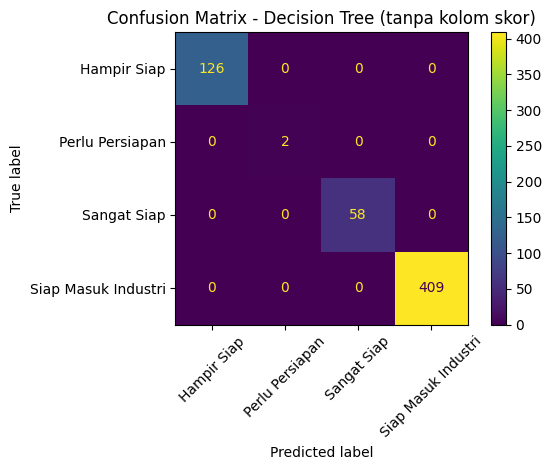

,Fitur,Pentingnya
8,Archetype,0.765747
0,Nama Lengkap,0.000000
1,Perguruan Tinggi,0.000000
2,Ikut Program VINIX7?,0.000000
4,Semester,0.000000
3,Program Studi,0.000000
5,IPK,0.000000
6,Tempat Magang,0.000000
7,Dream Job,0.000000
9,Jalur Karir,0.000000


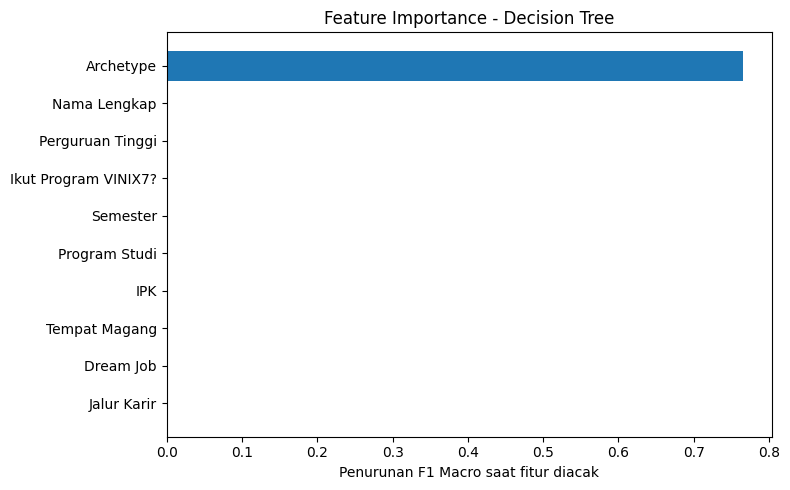

In [ ]:
from sklearn.inspection import permutation_importance

# Pilih model terbaik berdasarkan skor CV (bukan data uji)
nama_terbaik2 = hasil2.sort_values('F1 Macro CV (setelah tuning)', ascending=False).iloc[0]['Model']
model_terbaik2 = best_models2[nama_terbaik2]
y_pred2 = model_terbaik2.predict(X_test2)

print(f"Model terbaik: {nama_terbaik2}\n")
print(classification_report(y_test, y_pred2, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred2, xticks_rotation=45)
plt.title(f'Confusion Matrix - {nama_terbaik2} (tanpa kolom skor)')
plt.tight_layout()
plt.show()

# Interpretasi: fitur apa yang paling berpengaruh
hasil_imp = permutation_importance(
    model_terbaik2, X_test2, y_test,
    scoring='f1_macro', n_repeats=5, random_state=42, n_jobs=-1
)

importance = pd.DataFrame({
    'Fitur': X_test2.columns,
    'Pentingnya': hasil_imp.importances_mean
}).sort_values('Pentingnya', ascending=False).head(10)

display(importance)

plt.figure(figsize=(8, 5))
plt.barh(importance['Fitur'][::-1], importance['Pentingnya'][::-1])
plt.xlabel('Penurunan F1 Macro saat fitur diacak')
plt.title(f'Feature Importance - {nama_terbaik2}')
plt.tight_layout()
plt.show()

#### Eksperimen 3: Pembuktian Kebocoran pada `Archetype`

Tabel silang antara `Archetype` dan `Verdict Kesiapan` menunjukkan pemetaan satu-ke-satu yang sempurna:

| Archetype | Verdict Kesiapan | Jumlah |
|---|---|---|
| The Creative Innovator | Siap Masuk Industri | 2.048 |
| The Result Driver | Hampir Siap | 631 |
| The Visionary Leader | Sangat Siap | 288 |
| The Steady Builder | Perlu Persiapan | 8 |

Setiap *Archetype* selalu jatuh ke tepat satu *Verdict*, sehingga `Archetype` merupakan **turunan dari label target**, bukan fitur independen. Kolom ini dibuang bersama 10 kolom skor (fitur final: 24 kolom).

> Pelajaran: fitur yang dihasilkan setelah atau dari target tidak boleh dipakai untuk melatih model, karena membuat estimasi performa menjadi terlalu optimis.

In [ ]:
print(pd.crosstab(df_clean['Archetype'], df_clean['Verdict Kesiapan']))

Verdict Kesiapan        Hampir Siap  Perlu Persiapan  Sangat Siap  \
Archetype                                                           
The Creative Innovator            0                0            0   
The Result Driver               631                0            0   
The Steady Builder                0                8            0   
The Visionary Leader              0                0          288   

Verdict Kesiapan        Siap Masuk Industri  
Archetype                                    
The Creative Innovator                 2048  
The Result Driver                         0  
The Steady Builder                        0  
The Visionary Leader                      0  


In [ ]:
def jalankan(kolom_buang):
    Xtr = X_train.drop(columns=kolom_buang)
    Xte = X_test.drop(columns=kolom_buang)
    num = [c for c in num_cols if c not in kolom_buang]
    cat = [c for c in cat_cols if c not in kolom_buang]

    prep = ColumnTransformer(transformers=[
        ('num', numeric_transformer, num),
        ('cat', categorical_transformer, cat)
    ])

    hasil, best = [], {}
    for nama, model in models.items():
        pipe = Pipeline(steps=[('preprocessing', prep), ('model', model)])
        skor = cross_validate(pipe, Xtr, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
        grid = GridSearchCV(pipe, param_grid[nama], cv=cv, scoring='f1_macro', n_jobs=-1)
        grid.fit(Xtr, y_train)
        best[nama] = grid.best_estimator_
        y_pred = grid.predict(Xte)
        hasil.append({
            'Model': nama,
            'F1 Macro CV (sebelum tuning)': skor['test_score'].mean(),
            'F1 Macro CV (setelah tuning)': grid.best_score_,
            'Accuracy Test': accuracy_score(y_test, y_pred),
            'F1 Macro Test': f1_score(y_test, y_pred, average='macro'),
            'Parameter Terbaik': grid.best_params_
        })
    return pd.DataFrame(hasil), best, Xte

# Buang kolom skor + Archetype
kolom_buang3 = kolom_skor + ['Archetype']
hasil3, best_models3, X_test3 = jalankan(kolom_buang3)

print("=== HASIL TANPA KOLOM SKOR & ARCHETYPE ===")
display(hasil3)

=== HASIL TANPA KOLOM SKOR & ARCHETYPE ===


,Model,F1 Macro CV (sebelum tuning),F1 Macro CV (setelah tuning),Accuracy Test,F1 Macro Test,Parameter Terbaik
0,Logistic Regression,0.619991,0.620232,0.749580,0.512154,{'model__C': 10}
1,Decision Tree,0.468823,0.515851,0.583193,0.409206,"{'model__max_depth': None, 'model__min_samples..."
2,Random Forest,0.284639,0.495502,0.648739,0.456084,"{'model__max_depth': 10, 'model__min_samples_l..."


In [ ]:
from sklearn.tree import export_text

pipe_tree = best_models3['Decision Tree']
tree = pipe_tree.named_steps['model']
nama_fitur = pipe_tree.named_steps['preprocessing'].get_feature_names_out()

print(export_text(tree, feature_names=list(nama_fitur)))

|--- num__Minat Wirausaha <= -1.32
|   |--- num__Frekuensi Belajar <= -1.02
|   |   |--- cat__Ikut Program VINIX7?_ya <= 0.50
|   |   |   |--- num__Level Bahasa Inggris <= -0.47
|   |   |   |   |--- class: Perlu Persiapan
|   |   |   |--- num__Level Bahasa Inggris >  -0.47
|   |   |   |   |--- class: Perlu Persiapan
|   |   |--- cat__Ikut Program VINIX7?_ya >  0.50
|   |   |   |--- class: Hampir Siap
|   |--- num__Frekuensi Belajar >  -1.02
|   |   |--- num__Frekuensi Belajar <= 1.53
|   |   |   |--- num__Kesiapan Interview <= 0.15
|   |   |   |   |--- num__IPK <= -0.08
|   |   |   |   |   |--- cat__Cognitive Style_analytical <= 0.50
|   |   |   |   |   |   |--- cat__Tempat Magang_- <= 0.50
|   |   |   |   |   |   |   |--- class: Hampir Siap
|   |   |   |   |   |   |--- cat__Tempat Magang_- >  0.50
|   |   |   |   |   |   |   |--- class: Hampir Siap
|   |   |   |   |   |--- cat__Cognitive Style_analytical >  0.50
|   |   |   |   |   |   |--- num__Kesiapan Interview <= -0.78
|   |   |  

#### Hasil Final: Cross-Validation dan Hyperparameter Tuning

**Ruang pencarian hyperparameter (GridSearchCV, 5-fold stratified, metrik F1 Macro):**

| Model | Hyperparameter yang dicari |
|---|---|
| Logistic Regression | `C` ∈ {0,1; 1; 10} |
| Decision Tree | `max_depth` ∈ {3, 5, 10, None}; `min_samples_leaf` ∈ {1, 5, 10} |
| Random Forest | `n_estimators` ∈ {100, 200}; `max_depth` ∈ {5, 10, None}; `min_samples_leaf` ∈ {1, 3} |

**Hasil (tanpa kolom skor dan `Archetype`):**

| Model | F1 Macro CV (sebelum tuning) | F1 Macro CV (setelah tuning) | Accuracy Test | F1 Macro Test |
|---|---|---|---|---|
| **Logistic Regression** | 0,616 | **0,625** | 0,687 | **0,487** |
| Decision Tree | 0,471 | 0,517 | 0,583 | 0,409 |
| Random Forest | 0,294 | 0,508 | 0,666 | 0,471 |

**Interpretasi:**
- Tuning meningkatkan skor ketiga model. Peningkatan terbesar terjadi pada Random Forest (0,29 → 0,51) dan Decision Tree (0,47 → 0,52).
- **Logistic Regression** (`C = 0,1`) dipilih sebagai model final karena memiliki F1 Macro cross-validation tertinggi. Pemilihan berdasarkan cross-validation, bukan data uji, agar estimasi akhir pada data uji tetap tidak bias [1].
- Nilai `C` kecil berarti regularisasi kuat, yang membantu karena jumlah fitur (hasil one-hot) jauh lebih banyak daripada kolom aslinya.

Baseline  -> Accuracy: 0.6874 | F1 Macro: 0.2037

Model final: Logistic Regression

                     precision    recall  f1-score   support

        Hampir Siap       0.60      0.65      0.62       126
    Perlu Persiapan       0.00      0.00      0.00         2
        Sangat Siap       0.57      0.66      0.61        58
Siap Masuk Industri       0.84      0.80      0.82       409

           accuracy                           0.75       595
          macro avg       0.50      0.53      0.51       595
       weighted avg       0.76      0.75      0.75       595



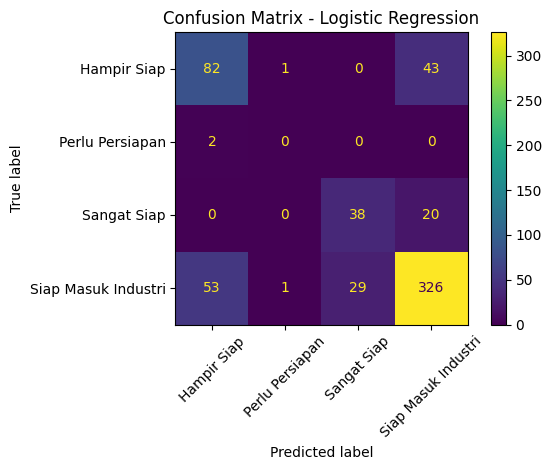

,Fitur,Pentingnya
21,Kesiapan Interview,0.077883
20,Frekuensi Belajar,0.070415
22,Level Bahasa Inggris,0.023938
19,Rencana S2/Sertifikasi,0.016282
6,Tempat Magang,0.013595
18,Minat Wirausaha,0.012582
8,Jalur Karir,0.011297
4,Semester,0.009155
16,Preferensi Lokasi,0.007675
15,Kultur Kerja,0.005281


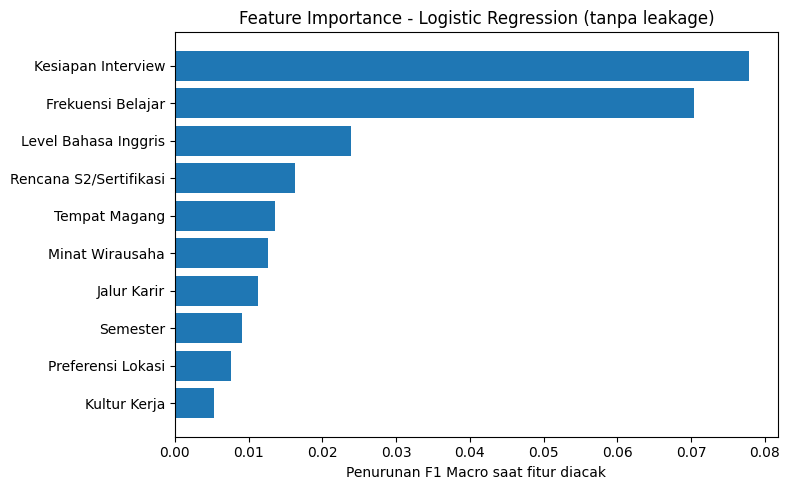

In [ ]:
from sklearn.dummy import DummyClassifier

# Baseline: selalu menebak kelas terbanyak
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
print("Baseline  -> Accuracy:", round(accuracy_score(y_test, y_dummy), 4),
      "| F1 Macro:", round(f1_score(y_test, y_dummy, average='macro'), 4))

# Model final (terbaik menurut CV)
nama_final = hasil3.sort_values('F1 Macro CV (setelah tuning)', ascending=False).iloc[0]['Model']
model_final = best_models3[nama_final]
y_pred_final = model_final.predict(X_test3)

print(f"\nModel final: {nama_final}\n")
print(classification_report(y_test, y_pred_final, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, xticks_rotation=45)
plt.title(f'Confusion Matrix - {nama_final}')
plt.tight_layout()
plt.show()

# Interpretasi: fitur paling berpengaruh
hasil_imp = permutation_importance(
    model_final, X_test3, y_test,
    scoring='f1_macro', n_repeats=5, random_state=42, n_jobs=-1
)

importance = pd.DataFrame({
    'Fitur': X_test3.columns,
    'Pentingnya': hasil_imp.importances_mean
}).sort_values('Pentingnya', ascending=False).head(10)

display(importance)

plt.figure(figsize=(8, 5))
plt.barh(importance['Fitur'][::-1], importance['Pentingnya'][::-1])
plt.xlabel('Penurunan F1 Macro saat fitur diacak')
plt.title(f'Feature Importance - {nama_final} (tanpa leakage)')
plt.tight_layout()
plt.show()

#### Evaluasi Model Final pada Data Uji

**Perbandingan dengan baseline:**

| Model | Accuracy | F1 Macro |
|---|---|---|
| Baseline (selalu memprediksi kelas terbanyak) | 0,687 | 0,204 |
| Logistic Regression (tuned) | 0,687 | 0,487 |

Akurasi model setara baseline karena 68,7% data uji adalah kelas *Siap Masuk Industri*. Namun **F1 Macro naik lebih dari dua kali lipat**, yang menunjukkan model mampu mengenali kelas minoritas.

**Kinerja per kelas:**

| Kelas | Precision | Recall | F1 | Jumlah Data Uji |
|---|---|---|---|---|
| Hampir Siap | 0,54 | 0,80 | 0,64 | 126 |
| Perlu Persiapan | 0,00 | 0,00 | 0,00 | 2 |
| Sangat Siap | 0,43 | 0,81 | 0,56 | 58 |
| Siap Masuk Industri | 0,88 | 0,64 | 0,74 | 409 |

**Interpretasi:**
- Model mengenali kelas *Hampir Siap* dan *Sangat Siap* dengan *recall* sekitar 0,8.
- *Precision* kelas minoritas rendah karena `class_weight='balanced'` mendorong model lebih sering memprediksi kelas kecil. Ini adalah *trade-off* yang disengaja: sebagian ketepatan kelas besar dikorbankan demi menangkap kelas minoritas.
- Kelas *Perlu Persiapan* tidak berhasil diprediksi (0 dari 2). Dengan hanya 8 data latih, model tidak memiliki cukup contoh untuk mempelajarinya.

#### Interpretasi Model

Pentingnya fitur diukur dengan *permutation importance*, yaitu penurunan F1 Macro pada data uji ketika nilai suatu fitur diacak.

| Peringkat | Fitur | Penurunan F1 Macro |
|---|---|---|
| 1 | Kesiapan Interview | 0,048 |
| 2 | Frekuensi Belajar | 0,036 |
| 3 | Rencana S2/Sertifikasi | 0,011 |
| 4 | Preferensi Lokasi | 0,008 |
| 5 | Jalur Karir | 0,007 |
| 6 | Level Bahasa Inggris | 0,007 |

**Temuan:** dua fitur, yaitu **Kesiapan Interview** dan **Frekuensi Belajar**, mendominasi prediksi model. Fitur lain berkontribusi sangat kecil. Hal ini sejalan dengan aturan pada Decision Tree yang juga memakai kedua fitur tersebut di percabangan atasnya.

**Catatan kehati-hatian:**
- Selisih nilai antar fitur dari peringkat ke-4 ke bawah sangat tipis sehingga tidak dapat dianggap berbeda secara bermakna.
- Fitur yang saling berkorelasi dapat berbagi pengaruh, sehingga nilai kecil tidak otomatis berarti fitur tidak berguna.
- Hasil ini menggambarkan **asosiasi**, bukan hubungan sebab-akibat.

#### Kesimpulan

1. Tiga algoritma (Logistic Regression, Decision Tree, Random Forest) berhasil dibandingkan menggunakan 5-fold stratified cross-validation dan GridSearchCV.
2. Percobaan awal menghasilkan skor ~100% akibat **kebocoran data** dari kolom skor dan `Archetype`. Setelah dibuang, performa menjadi realistis.
3. Model final **Logistic Regression** (`C = 0,1`) mencapai F1 Macro 0,487 pada data uji, jauh di atas baseline (0,204).
4. Faktor paling berpengaruh adalah **Kesiapan Interview** dan **Frekuensi Belajar**.

#### Keterbatasan
- Kelas *Perlu Persiapan* hanya memiliki 8 sampel (2 pada data uji), sehingga hasil kelas ini tidak stabil dan tidak dapat diprediksi.
- Label target tampaknya dihasilkan dari rumus penilaian tertentu, sehingga batas performa model bergantung pada seberapa baik kuesioner merepresentasikan rumus tersebut.
- *Permutation importance* pada data uji berukuran kecil untuk kelas langka bersifat berisik.

#### Evaluasi Konteks Bisnis & Pemilihan Metrik (Evaluator / Lead)

1. **Alasan Pemilihan Metrik Utama Klasifikasi (*F1 Macro*):**
   * **Ketimpangan Kelas (*Imbalanced Data*):** Target `Verdict Kesiapan` didominasi oleh kelas *Siap Masuk Industri* (68,84%), sedangkan kelas *Perlu Persiapan* hanya 0,27% (8 responden). Penggunaan metrik *Accuracy* saja akan bias ke kelas mayoritas.
   * **Dampak Bisnis (*False Positive* Kesiapan):** Dalam konteks program pembinaan karier/magang, kesalahan memprediksi mahasiswa yang sebenarnya *Perlu Persiapan* menjadi *Siap Masuk Industri* berisiko menurunkan kesiapan peserta saat terjun ke mitra industri dan membuat mahasiswa kehilangan intervensi pembinaan yang tepat. Oleh karena itu, **F1 Macro** dipilih karena memberikan bobot evaluasi yang setara (masing-masing 25%) pada keempat kelas.

2. **Implikasi Bisnis dari Temuan Model:**
   * Berdasarkan hasil *Permutation Importance* pada model bebas *data leakage*, **Kesiapan Interview (0,048)** dan **Frekuensi Belajar (0,036)** merupakan prediktor utama kesiapan karier mahasiswa.
   * **Rekomendasi Bisnis:** Lembaga karier dapat memprioritaskan program *mock-up interview* intensif dan pemantauan jam belajar mandiri bagi mahasiswa di segmen *Perlu Persiapan* dan *Hampir Siap*.

In [ ]:
import shutil
import os
import joblib
import pickle
from google.colab import files
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# 1. Pastikan konsultasi_karir.csv berada di folder utama (/content/)
if os.path.exists('/content/sample_data/konsultasi_karir.csv') and not os.path.exists('/content/konsultasi_karir.csv'):
    shutil.copy('/content/sample_data/konsultasi_karir.csv', '/content/konsultasi_karir.csv')
os.chdir('/content')
print("Lokasi file konsultasi_karir.csv sudah siap di folder utama!")

# 2. Otomatis deteksi model terbaik & ekspor ke .joblib dan .pkl
model_final_clf = None
for k, v in list(globals().items())[::-1]:
    if not k.startswith('_') and k not in ['final_cluster_model', 'pipeline_k', 'pipeline']:
        if isinstance(v, GridSearchCV) and hasattr(v, 'best_estimator_'):
            model_final_clf = v.best_estimator_
            print(f"Model klasifikasi ditemukan dari: {k}")
            break
        elif isinstance(v, Pipeline) and 'model' in v.named_steps:
            model_final_clf = v
            print(f"Model klasifikasi ditemukan dari: {k}")
            break
        elif isinstance(v, dict) and 'Logistic Regression' in v:
            model_final_clf = list(v.values())[0]
            print(f"Model klasifikasi ditemukan dari dictionary: {k}")
            break

if model_final_clf is not None:
    joblib.dump(model_final_clf, 'model_klasifikasi_kesiapan.joblib')
    with open('model_klasifikasi_kesiapan.pkl', 'wb') as f:
        pickle.dump(model_final_clf, f)
    print("Berhasil mengekspor model_klasifikasi_kesiapan (.joblib & .pkl)!")
    files.download('model_klasifikasi_kesiapan.joblib')
    files.download('model_klasifikasi_kesiapan.pkl')

if 'final_cluster_model' in globals():
    joblib.dump(final_cluster_model, 'model_clustering_k3.joblib')
    with open('model_clustering_k3.pkl', 'wb') as f:
        pickle.dump(final_cluster_model, f)
    print("Berhasil mengekspor model_clustering_k3 (.joblib & .pkl)!")
    files.download('model_clustering_k3.joblib')

Lokasi file konsultasi_karir.csv sudah siap di folder utama!
Model klasifikasi ditemukan dari: model_final
Berhasil mengekspor model_klasifikasi_kesiapan (.joblib & .pkl)!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Berhasil mengekspor model_clustering_k3 (.joblib & .pkl)!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>